# VisionGuard AI
### AI-Powered Object Detection and Tracking System

**Objective:** Develop a computer vision system that detects objects
in video footage, tracks their movement, and identifies predefined
security-related events.

### Day 1: Object Detection Baseline
- YOLO-based object detection
- Video input processing
- Bounding box visualization
- Confidence scores
- Annotated video output

In [4]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [12]:
OUTPUT_DIR = PROJECT_DIR / "outputs" / "processed_videos"
SCREENSHOT_DIR = PROJECT_DIR / "outputs" / "screenshots"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SCREENSHOT_DIR.mkdir(parents=True, exist_ok=True)

print("Processed videos folder:", OUTPUT_DIR.is_dir())
print("Screenshots folder:", SCREENSHOT_DIR.is_dir())

Processed videos folder: True
Screenshots folder: True


In [13]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("YOLO11n model loaded successfully!")

YOLO11n model loaded successfully!


In [15]:
print("Current directory:", Path.cwd())
print("Expected video path:", VIDEO_PATH)
print("Video exists:", VIDEO_PATH.exists())

print("\nVideos inside input_videos:")
for file in (PROJECT_DIR / "data" / "input_videos").iterdir():
    print(file.name, "|", file.is_file(), "|", file.stat().st_size, "bytes")

Current directory: d:\Real Object Detection
Expected video path: d:\Real Object Detection\data\input_videos\test.mp4
Video exists: True

Videos inside input_videos:
test.mp4 | True | 0 bytes
video_2026-11-22_01-04-10.mp4 | True | 12516733 bytes


In [16]:
# Project paths

PROJECT_DIR = Path.cwd()

VIDEO_PATH = PROJECT_DIR / "data" / "input_videos" / "video_2026-11-22_01-04-10.mp4"

OUTPUT_DIR = PROJECT_DIR / "outputs" / "processed_videos"
SCREENSHOT_DIR = PROJECT_DIR / "outputs" / "screenshots"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SCREENSHOT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Video path:", VIDEO_PATH)
print("Video exists:", VIDEO_PATH.exists())

Project directory: d:\Real Object Detection
Video path: d:\Real Object Detection\data\input_videos\video_2026-11-22_01-04-10.mp4
Video exists: True


In [17]:
# Run YOLO object detection on the video

results = model.predict(
    source=str(VIDEO_PATH),
    conf=0.35,
    imgsz=640,
    verbose=False
)

print("Detection completed successfully!")
print("Frames processed:", len(results))

WARNING 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Detection completed successfully!
Frames processed: 924


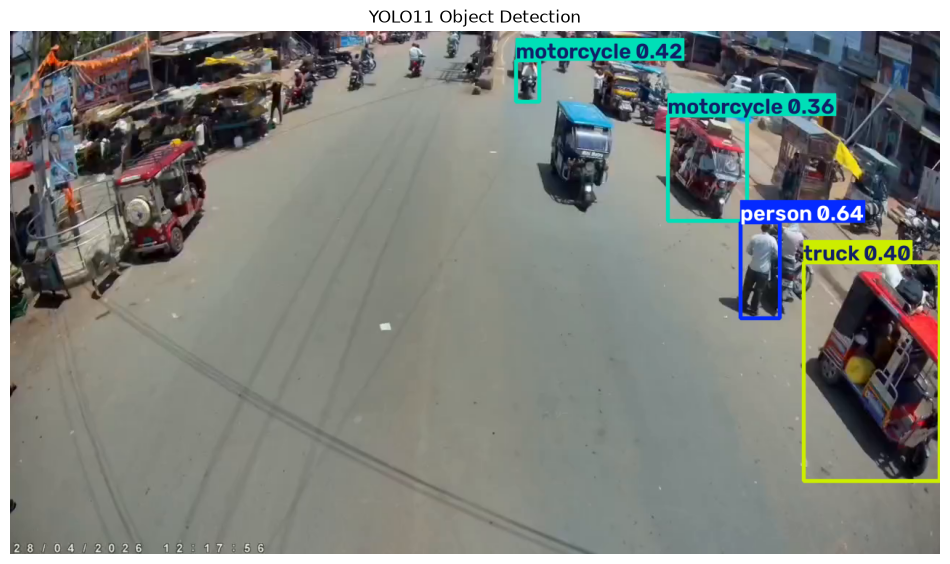

In [18]:
# Visualize the first frame with YOLO detections

annotated_frame = results[0].plot()

annotated_rgb = cv2.cvtColor(
    annotated_frame,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 7))
plt.imshow(annotated_rgb)
plt.title("YOLO11 Object Detection")
plt.axis("off")
plt.show()


In [19]:
# Save YOLO annotated video

output_video_path = OUTPUT_DIR / "detection_output.mp4"

cap = cv2.VideoCapture(str(VIDEO_PATH))

fps = cap.get(cv2.CAP_PROP_FPS)
cap.release()

# Get frame dimensions from the first result
first_frame = results[0].plot()
height, width = first_frame.shape[:2]

writer = cv2.VideoWriter(
    str(output_video_path),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

for result in results:
    frame = result.plot()
    writer.write(frame)

writer.release()

print("Annotated video saved at:", output_video_path)
print("Video saved successfully:", output_video_path.exists())

Annotated video saved at: d:\Real Object Detection\outputs\processed_videos\detection_output.mp4
Video saved successfully: True
